In [117]:
import pandas as pd
from sklearn.impute import SimpleImputer
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder , OneHotEncoderD
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score , precision_score , recall_score , f1_score , confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [94]:
df = pd.read_csv("loan_approval_data.csv")

df.sample(20)
#df.isnull().sum()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
918,919.0,12395.0,5901.0,Self-employed,52.0,Single,0.0,705.0,2.0,0.21,16226.0,30540.0,39869.0,48.0,Personal,Rural,Not Graduate,Male,Private,Yes
367,368.0,9390.0,5658.0,Unemployed,39.0,Married,1.0,558.0,1.0,0.13,17165.0,24364.0,NaN,72.0,Home,Urban,Graduate,Male,Business,No
764,765.0,11865.0,4616.0,Contract,47.0,Married,2.0,687.0,3.0,0.60,2970.0,20927.0,9968.0,84.0,Personal,Urban,Not Graduate,Female,Unemployed,No
899,900.0,9973.0,NaN,Salaried,44.0,Married,1.0,704.0,0.0,0.36,9304.0,2377.0,18776.0,48.0,Business,Semiurban,Graduate,Male,Unemployed,Yes
288,289.0,9206.0,6924.0,Salaried,27.0,Single,0.0,635.0,3.0,0.39,15588.0,22553.0,21425.0,48.0,Personal,Semiurban,Graduate,Female,Private,No
646,647.0,18907.0,3719.0,Contract,52.0,Married,0.0,619.0,3.0,0.55,672.0,39617.0,3389.0,48.0,Home,Rural,Not Graduate,Female,Government,No
596,597.0,8996.0,1939.0,Salaried,21.0,Single,1.0,674.0,0.0,0.22,19814.0,43118.0,26188.0,24.0,Education,Rural,Not Graduate,Male,Government,NaN
351,352.0,10130.0,9098.0,Salaried,45.0,Single,3.0,651.0,0.0,NaN,329.0,35367.0,20739.0,24.0,Home,Semiurban,Graduate,Male,Business,Yes
103,104.0,19868.0,329.0,Contract,50.0,Married,2.0,747.0,0.0,0.22,16279.0,8065.0,18993.0,12.0,Education,Urban,Graduate,Female,Unemployed,Yes
355,NaN,9253.0,NaN,Self-employed,44.0,Married,1.0,728.0,1.0,0.22,5266.0,41190.0,7579.0,NaN,Car,Urban,Graduate,Male,NaN,Yes


In [3]:
categorical_values =df.select_dtypes(include = ["object"]).columns
numerical_values = df.select_dtypes(include = ["float64"]).columns 

In [4]:
categorical_values

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [5]:
numerical_values

Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [6]:
categorical_values.size+numerical_values.size

20

In [7]:
cat_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_values] = cat_imp.fit_transform(df[categorical_values])

In [8]:
num_imp = SimpleImputer(strategy = "mean")
df[numerical_values] = num_imp.fit_transform(df[numerical_values])

In [9]:
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


[Text(0, 0, '702'), Text(0, 0, '298')]

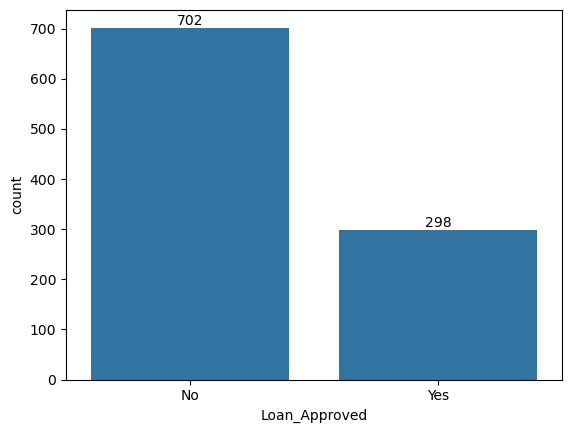

In [10]:
#how many loan will approved 
num_dat=df["Loan_Approved"].value_counts()
ax = sns.barplot(num_dat)
ax.bar_label(ax.containers[0])


<Axes: xlabel='Applicant_Income', ylabel='Count'>

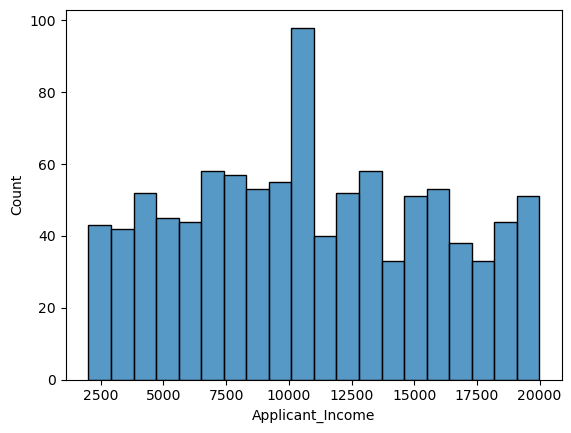

In [11]:
# how many loan pass depend on income
sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20
)


<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

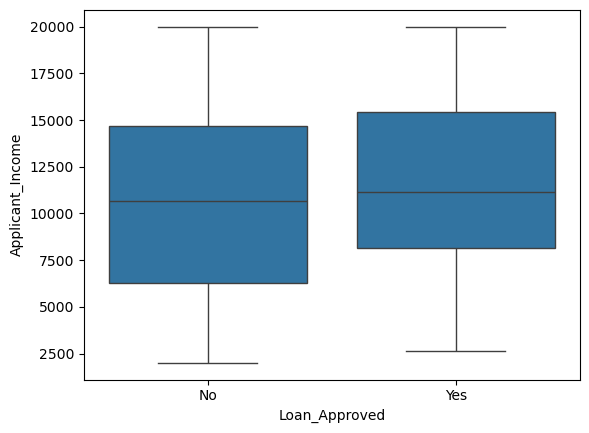

In [12]:
sns.boxplot(
    data = df,
    x = "Loan_Approved",
    y = "Applicant_Income"
    
)

<Axes: xlabel='Loan_Approved', ylabel='Loan_Amount'>

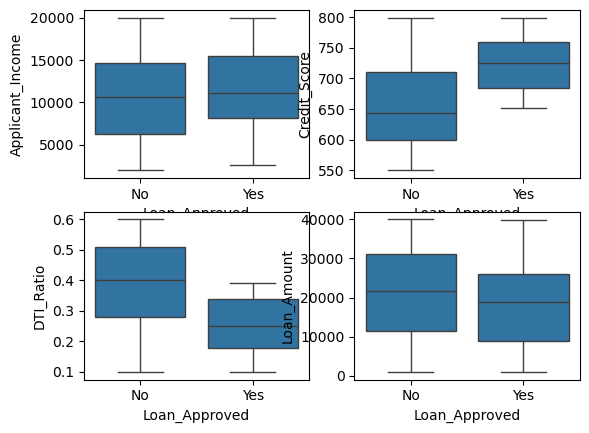

In [13]:
fig , axes = plt.subplots(2,2)
sns.boxplot(ax = axes[0,0] , data=df, x = "Loan_Approved" , y = "Applicant_Income")
sns.boxplot(ax = axes[0,1] , data=df, x = "Loan_Approved" , y = "Credit_Score")
sns.boxplot(ax = axes[1,0] , data=df, x = "Loan_Approved" , y = "DTI_Ratio")
sns.boxplot(ax = axes[1,1] , data=df, x = "Loan_Approved" , y = "Loan_Amount")

<Axes: xlabel='Credit_Score', ylabel='Count'>

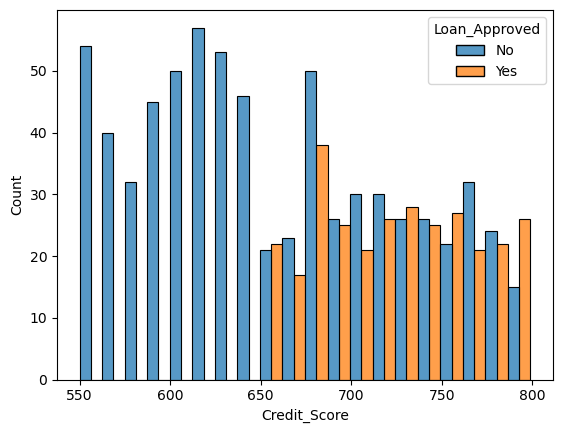

In [14]:
# which civil score loan was approved 
sns.histplot(
    data=df,
    x="Credit_Score",
    hue = "Loan_Approved",
    bins = 20,
    multiple = "dodge"
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

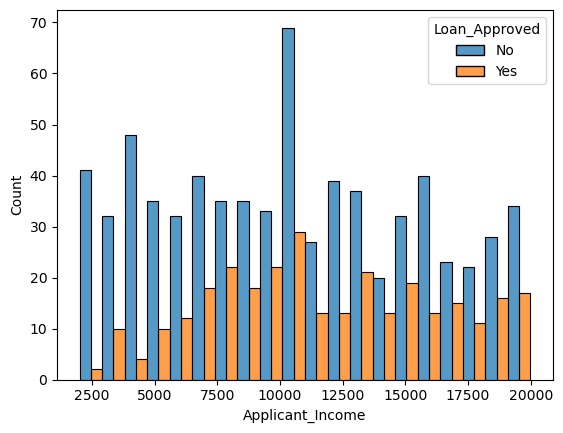

In [15]:
sns.histplot(
    data=df,
    x="Applicant_Income",
    hue = "Loan_Approved",
    multiple = "dodge",
    bins = 20
)

In [17]:
df.drop("Applicant_ID" , axis = 1)

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.000000,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.000000,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.000000,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.000000,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.000000,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.000000,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.000000,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.000000,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.000000,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.000000,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,10852.571579,9092.0,Salaried,58.0,Married,0.0,557.0,0.0,0.59,5370.000000,43563.0,8311.0,72.0,Personal,Urban,Not Graduate,Male,Unemployed,No
996,3279.000000,6356.0,Self-employed,58.0,Married,1.0,646.0,3.0,0.19,9940.452632,18361.0,22563.0,12.0,Business,Urban,Graduate,Female,Government,No
997,15192.000000,8433.0,Contract,48.0,Single,1.0,666.0,1.0,0.40,8581.000000,41335.0,16203.0,24.0,Home,Rural,Graduate,Male,MNC,No
998,9083.000000,7380.0,Unemployed,50.0,Single,1.0,748.0,3.0,0.31,13491.000000,8933.0,10290.0,36.0,Personal,Urban,Graduate,Male,Private,Yes


In [ ]:
df.head()
df.info()

In [47]:
le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"]) 
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])


In [ ]:
cols = ["Employment_Status" , "Loan_Purpose" , "Property_Area" , "Gender" , "Employer_Category" ,]
ohe = OneHotEncoder(drop = "first" , sparse_output = False , handle_unknown = "ignore")
encoded = ohe.fit_transform(df[cols])
encoded_df = pd.DataFrame(encoded , columns = ohe.get_feature_names_out(cols) , index = df.index )

In [49]:
encoded_df.head()

,Employment_Status_Salaried,Employment_Status_Self-employed,Employment_Status_Unemployed,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [44]:
df = pd.concat([df.drop(columns = cols) ,encoded_df] , axis = 1)

In [59]:
df=df.drop("Marital_Status" ,  axis = 1)

In [60]:
df.info ()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_ID                     1000 non-null   float64
 1   Applicant_Income                 1000 non-null   float64
 2   Coapplicant_Income               1000 non-null   float64
 3   Age                              1000 non-null   float64
 4   Dependents                       1000 non-null   float64
 5   Credit_Score                     1000 non-null   float64
 6   Existing_Loans                   1000 non-null   float64
 7   DTI_Ratio                        1000 non-null   float64
 8   Savings                          1000 non-null   float64
 9   Collateral_Value                 1000 non-null   float64
 10  Loan_Amount                      1000 non-null   float64
 11  Loan_Term                        1000 non-null   float64
 12  Education_Level      

In [63]:
nums_cols = df.select_dtypes(include = "number")
corr_matrix = nums_cols.corr()

In [69]:
corr_matrix["Loan_Approved"].sort_values(ascending = False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Applicant_ID                      -0.011167
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

In [73]:
# Train Test Split
x = df.drop("Loan_Approved" , axis = 1)
y = df["Loan_Approved"]

In [75]:
x_train , x_test , y_train , y_test = train_test_split(
    x,y, test_size = 0.25, random_state=42
)

In [76]:
x_train.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
82,83.0,14666.0,5760.0,28.0,2.0,752.0,2.000000,0.58,15390.000000,20092.0,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
991,992.0,13382.0,7638.0,28.0,3.0,723.0,1.950526,0.30,8930.000000,10336.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
789,790.0,10007.0,8853.0,41.0,1.0,694.0,1.000000,0.17,9940.452632,43858.0,...,0.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
894,895.0,15224.0,5435.0,54.0,3.0,560.0,4.000000,0.52,18738.000000,14551.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
398,399.0,13261.0,6342.0,50.0,0.0,606.0,3.000000,0.49,13746.000000,45210.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [101]:
Scaler = StandardScaler()
x_train_scaled = Scaler.fit_transform(x_train)
x_test_scaled = Scaler.transform(x_test)

In [82]:
x_train_scaled

array([[-1.48549835e+00,  7.57115318e-01,  2.21894813e-01, ...,
        -4.16784021e-01, -8.62662186e-01, -3.13203819e-01],
       [ 1.74253493e+00,  4.98274469e-01,  8.77567315e-01, ...,
        -4.16784021e-01,  1.15920231e+00, -3.13203819e-01],
       [ 1.02519420e+00, -1.82089912e-01,  1.30176438e+00, ...,
        -4.16784021e-01, -8.62662186e-01, -3.13203819e-01],
       ...,
       [ 1.27732881e+00, -2.27245948e-01,  3.40251032e-01, ...,
        -4.16784021e-01,  1.15920231e+00, -3.13203819e-01],
       [-3.18944366e-04,  1.12924944e+00, -4.75673695e-01, ...,
        -4.16784021e-01, -8.62662186e-01, -3.13203819e-01],
       [-1.41447451e+00, -1.75468918e+00,  4.03557966e-03, ...,
         2.39932423e+00, -8.62662186e-01, -3.13203819e-01]],
      shape=(750, 27))

In [96]:
# train models 
#logistic regression
model = LogisticRegression()
model.fit(x_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [108]:
y_pred = model.predict(x_test_scaled)
print(f"accuracy score is {accuracy_score(y_pred , y_test) * 100} %")
print(f"precision score is {precision_score(y_pred , y_test) * 100} %")
print(f"f1 score is {f1_score(y_pred , y_test) * 100} %")
print(f"recall score is {recall_score(y_pred , y_test) * 100} %")
print(f"confusion matrics is {confusion_matrix(y_pred , y_test) * 100} %")

accuracy score is 86.8 %
precision score is 75.0 %
f1 score is 77.55102040816327 %
recall score is 80.28169014084507 %
confusion matrics is [[16000  1900]
 [ 1400  5700]] %


In [115]:
#knn model
knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(x_train_scaled,y_train)
y_predict = knn_model.predict(x_test_scaled)
print(f"accuracy score is {accuracy_score(y_predict , y_test) * 100} %")
print(f"precision score is {precision_score(y_predict , y_test) * 100} %")
print(f"f1 score is {f1_score(y_predict , y_test) * 100} %")
print(f"recall score is {recall_score(y_predict , y_test) * 100} %")
print(f"confusion matrics is {confusion_matrix(y_predict , y_test) * 100} %")

# very worst condition

accuracy score is 76.0 %
precision score is 46.05263157894737 %
f1 score is 53.84615384615385 %
recall score is 64.81481481481481 %
confusion matrics is [[15500  4100]
 [ 1900  3500]] %


In [118]:
#naive bayes  model
naive_model = GaussianNB()
naive_model.fit(x_train_scaled,y_train)
y_predic = naive_model.predict(x_test_scaled)
print(f"accuracy score is {accuracy_score(y_predic , y_test) * 100} %")
print(f"precision score is {precision_score(y_predic , y_test) * 100} %")
print(f"f1 score is {f1_score(y_predic , y_test) * 100} %")
print(f"recall score is {recall_score(y_predic , y_test) * 100} %")
print(f"confusion matrics is {confusion_matrix(y_predic , y_test) * 100}
#less then logistic regression 
      

accuracy score is 85.2 %
precision score is 64.47368421052632 %
f1 score is 72.5925925925926 %
recall score is 83.05084745762711 %
confusion matrics is [[16400  2700]
 [ 1000  4900]] %
